# Projeto
O projeto Agroscope (IA) visa introduzir visão computacional para identificar padrões estruturais e texturas em folhas de plantas, de modo a identificar possíveis pragas.

Esta versão usa **YOLO (detecção de objetos)** no lugar da classificação: além de dizer *qual* doença existe na folha, o modelo aponta **onde** (o segmento/caixa) a lesão foi encontrada.

## Importando Classes

In [1]:
# Torch
import torch
import torchvision.datasets as datasets
from torch.utils.data import random_split, Subset

# YOLO
from ultralytics import YOLO

# Numpy / Pandas
import numpy as np
import pandas as pd

import random
import shutil
import json
import os

# Módulos Próprios
from utils.yolo import Lesion_Boxes, Export_Split, Write_Data_Yaml, Leaf_Region

from dotenv import load_dotenv

In [2]:
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)
print(".env loaded sucessfully" if load_dotenv() else "couldn't load .env")

.env loaded sucessfully


# Definições

In [3]:
# Pesos pré-treinados no COCO -> transfer-learning para as lesões
NET = YOLO("yolo11s.pt")

In [4]:
# Device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# YOLO precisa de mais épocas que a classificação (a cabeça de detecção parte do zero p/ nossas classes)
EPOCH = 30
PATIENCE = 10  # early stopping: para se o mAP de validação não melhorar por N épocas

BATCH_SIZE = 32
IMG_SIZE = 256  # as imagens do dataset têm 128-256px

# Learning Rate / Congelamento
LR0 = 1e-3
FREEZE = 10  # congela as 10 primeiras camadas (backbone), equivalente ao "descongelar só as últimas" do lab

# Confiança mínima para considerar uma detecção como lesão
CONF = 0.25

HEALTHY = "Healthy"

DATA_PATH = os.getenv("DATA_PATH")
EVAL_PATH = os.getenv("EVAL_PATH")

YOLO_DATA_PATH = os.getenv("YOLO_DATA_PATH", "./Treinamento/Yolo/dataset")
YOLO_RUNS_PATH = os.getenv("YOLO_RUNS_PATH", "./Treinamento/Yolo/runs")
YOLO_MODEL_PATH = os.getenv("YOLO_MODEL_PATH", "./Models/Saved/Expert/Coffee/coffee_yolo.pt")

print(f"Dispositivo Usado: {"GPU" if DEVICE.type == "cuda" else "CPU"}")

Dispositivo Usado: GPU


## Dataset Principal

Usamos o `ImageFolder` apenas para listar caminhos e classes — as transformações/augmentations agora são feitas internamente pelo YOLO.

In [5]:
dataset = datasets.ImageFolder(root=DATA_PATH)
num_labels = len(dataset.classes)

# Classes de detecção = apenas as doenças. "Healthy" não tem caixa: é a ausência de detecção.
det_classes = [c for c in dataset.classes if c != HEALTHY]
det_class_to_idx = {c: i for i, c in enumerate(det_classes)}

print("Classes do dataset:", dataset.classes)
print("Classes de detecção:", det_class_to_idx)

Classes do dataset: ['Healthy', 'Phoma', 'Rust']
Classes de detecção: {'Phoma': 0, 'Rust': 1}


In [6]:
# Pode ser simplificado
class Balance:
    def __init__(self):
        pass

    def __call__(self, value :int=None):
        class_indices = {}
        for label in range(num_labels):
            class_indices[label] = []

        for idx, (_, label) in enumerate(dataset.imgs):
            class_indices[label].append(idx)


        low = value
        for _, imgs in class_indices.items():
            if low == None:
                low = len(imgs)
            else:
                if low >= len(imgs):
                    low = len(imgs)
                else:
                    continue

        return class_indices, low


class_indices, low = Balance().__call__(1200)

In [7]:
balanced_indices = []

for class_label, indices in class_indices.items():
    if len(indices) > low:
        random.shuffle(indices)
        selected_indices = indices[:low]
    else:
        selected_indices = indices

    balanced_indices.extend(selected_indices)
    print(f"Class {class_label}: {len(selected_indices)}")

random.shuffle(balanced_indices)
balanced_dataset = Subset(dataset, balanced_indices)

Class 0: 1074
Class 1: 1074
Class 2: 1074


In [8]:
dataset_len = len(balanced_dataset)

train_size = int(0.7 * dataset_len)
val_size = int(0.15 * dataset_len)
test_size = dataset_len - train_size - val_size

print(f"All Dataset: {dataset_len}")
print(f"Train (70%): {train_size}")
print(f"Eval (15%): {val_size}")
print(f"Test (15%): {test_size}")

All Dataset: 3222
Train (70%): 2255
Eval (15%): 483
Test (15%): 484


In [9]:
train_dataset, val_dataset, test_dataset = random_split(
    balanced_dataset, [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
    )

def To_Samples(split):
    """Subset(random_split) -> Subset(balanced) -> ImageFolder: devolve [(caminho, nome_da_classe)]"""
    return [(dataset.imgs[balanced_indices[i]][0], dataset.classes[dataset.imgs[balanced_indices[i]][1]])
            for i in split.indices]

train_samples = To_Samples(train_dataset)
val_samples = To_Samples(val_dataset)
test_samples = To_Samples(test_dataset)

print(f"Split -> train={len(train_samples)} val={len(val_samples)} test={len(test_samples)}")

Split -> train=2255 val=483 test=484


## Rótulos de Detecção (pseudo-labels)
O dataset só tem rótulo por **pasta** (classificação), não tem caixas desenhadas à mão. Para treinar o YOLO, as caixas são geradas automaticamente por `Lesion_Boxes` (em `utils/yolo.py`):

- Converte a imagem para **Lab** e usa o canal **a\*** (verde ↔ vermelho). Folha sadia é verde; lesões de ferrugem/phoma são laranja/marrom/roxas.
- Limiar adaptativo (mediana da imagem + delta) para lidar com fotos desbotadas.
- Cada região conexa relevante vira uma caixa com a classe da pasta.
- `Healthy` vira imagem **sem caixa** (fundo) e imagens doentes em que nenhuma lesão foi encontrada são **descartadas** do treino.

⚠️ São rótulos fracos: confira a visualização abaixo. Se as caixas estiverem ruins para algum tipo de foto, ajuste `delta`/`thr_min`/`thr_max` em `Lesion_Boxes` — ou, idealmente, revise/anote parte das imagens manualmente (ex. CVAT, Label Studio) e substitua os `.txt`.

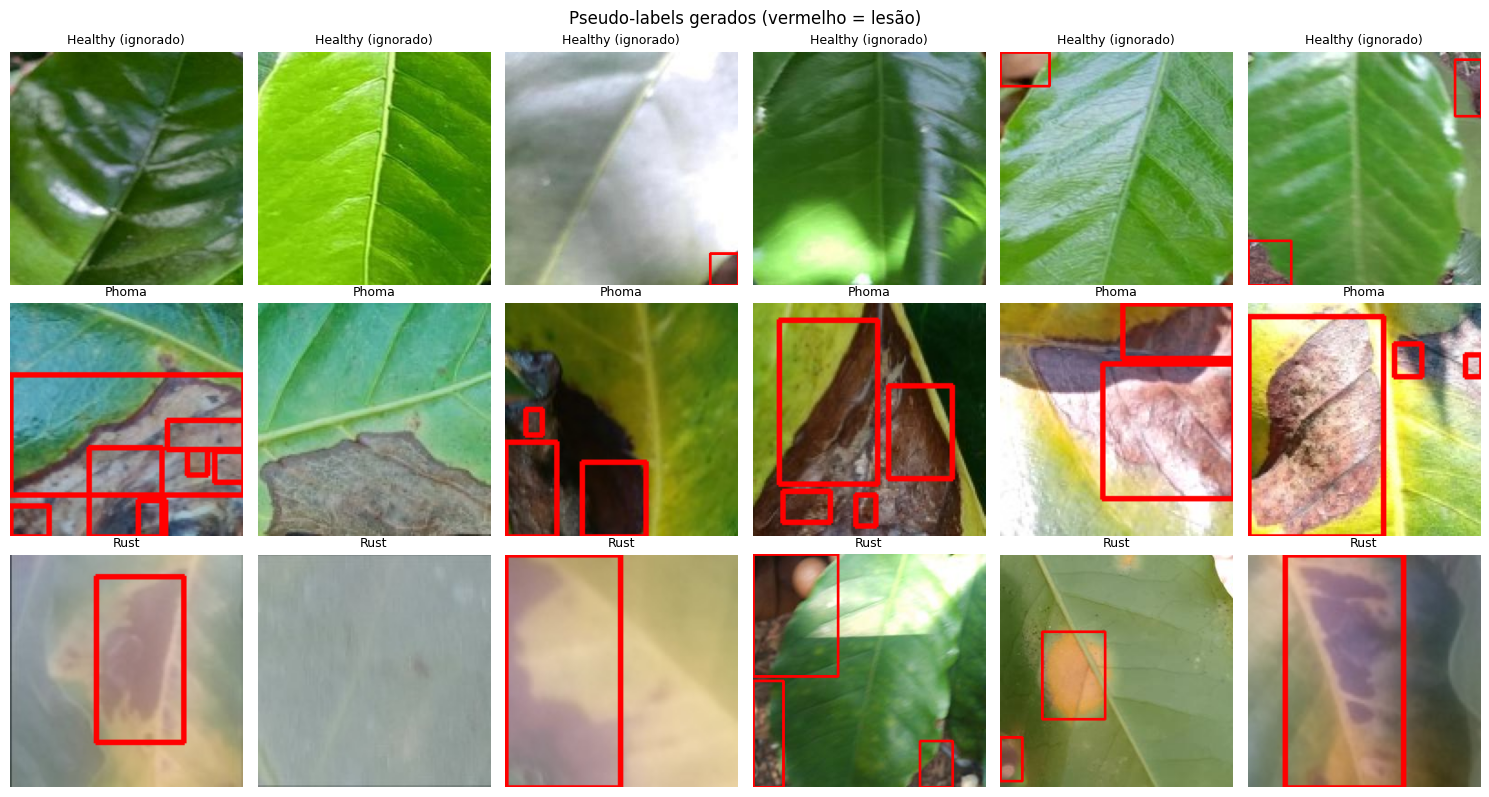

In [10]:
import cv2
import matplotlib.pyplot as plt

def Draw_Pseudo(path):
    img = cv2.imread(path)
    for x, y, w, h in Lesion_Boxes(img):
        cv2.rectangle(img, (x, y), (x + w, y + h), (0, 0, 255), 2)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

n_cols = 6
fig, axes = plt.subplots(len(dataset.classes), n_cols, figsize=(2.5 * n_cols, 2.7 * len(dataset.classes)))

for row, class_name in enumerate(dataset.classes):
    picks = random.sample([s for s in train_samples if s[1] == class_name], n_cols)
    for col, (path, _) in enumerate(picks):
        axes[row, col].imshow(Draw_Pseudo(path))
        axes[row, col].set_title(class_name if class_name != HEALTHY else f"{HEALTHY} (ignorado)", fontsize=9)
        axes[row, col].axis("off")

plt.suptitle("Pseudo-labels gerados (vermelho = lesão)")
plt.tight_layout()
plt.show()

In [11]:
# Recria o dataset YOLO do zero (evita misturar com execuções anteriores)
if os.path.isdir(YOLO_DATA_PATH):
    shutil.rmtree(YOLO_DATA_PATH)

for split, samples in [("train", train_samples), ("val", val_samples), ("test", test_samples)]:
    stats = Export_Split(samples, split, YOLO_DATA_PATH, det_class_to_idx, healthy=HEALTHY)
    print(f"{split:>5}: {stats['written']} imagens | {stats['boxes']} caixas | {stats['skipped']} descartadas (doentes sem lesão detectada)")

DATA_YAML = Write_Data_Yaml(YOLO_DATA_PATH, det_classes)
print(open(DATA_YAML).read())

train: 2095 imagens | 2590 caixas | 160 descartadas (doentes sem lesão detectada)
  val: 438 imagens | 549 caixas | 45 descartadas (doentes sem lesão detectada)
 test: 450 imagens | 552 caixas | 34 descartadas (doentes sem lesão detectada)
path: /home/kaua-matheus/Documents/Agroscope_IA/Steps/Treinamento/Yolo/dataset
train: images/train
val: images/val
test: images/test
names:
  0: Phoma
  1: Rust



# Modelo
Usaremos um YOLO já treinado (COCO) para realizar transfer-learning: o backbone congelado mantém o entendimento de bordas/texturas, e as camadas finais (neck + head) aprendem a localizar as lesões.

# Treinando o modelo

In [12]:
train_results = NET.train(
    data=DATA_YAML,
    epochs=EPOCH,
    patience=PATIENCE,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=0 if DEVICE.type == "cuda" else "cpu",
    workers=4,

    # Otimizador
    optimizer="AdamW",
    lr0=LR0,
    cos_lr=True,  # equivalente ao CosineAnnealingLR do lab
    weight_decay=1e-4,
    freeze=FREEZE,

    # Augmentation (folhas não têm orientação fixa)
    fliplr=0.5,
    flipud=0.5,

    seed=42,
    deterministic=True,
    project=os.path.abspath(YOLO_RUNS_PATH),
    name="coffee",
    exist_ok=True,
    plots=True,
)

RUN_DIR = str(train_results.save_dir)
print("Resultados salvos em:", RUN_DIR)

New https://pypi.org/project/ultralytics/8.4.182 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.174 🚀 Python-3.12.3 torch-2.11.0+cu130 CUDA:0 (NVIDIA GeForce RTX 3060, 11910MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=./Treinamento/Yolo/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=256, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=y

## Diagnóstico de Overfitting (curvas de treino vs. validação)
Como ler o gráfico abaixo:
- **Loss de treino caindo e loss de validação subindo (ou estagnada)** = overfitting claro. A partir da época em que a linha de validação vira pra cima, o modelo está decorando o treino.
- **As duas caindo juntas, com um gap pequeno e estável** = sem overfitting relevante.
- **mAP de validação estagnado/caindo** enquanto a loss de treino ainda cai = o próximo sinal de overfitting (o early stopping corta aqui).

A loss do YOLO é a soma de `box` (posição da caixa) + `cls` (classe) + `dfl` (refinamento das bordas).

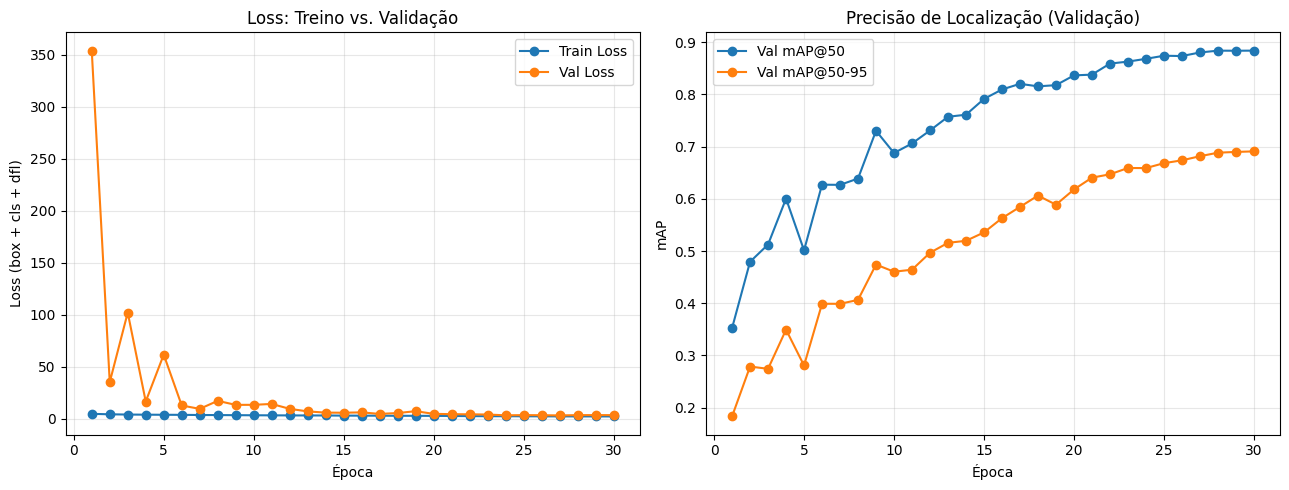

Gap final (val_loss - train_loss): 1.2500


In [13]:
history = pd.read_csv(os.path.join(RUN_DIR, "results.csv"))
history.columns = history.columns.str.strip()

history["train_loss"] = history[["train/box_loss", "train/cls_loss", "train/dfl_loss"]].sum(axis=1)
history["val_loss"] = history[["val/box_loss", "val/cls_loss", "val/dfl_loss"]].sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(history["epoch"], history["train_loss"], label="Train Loss", marker="o")
axes[0].plot(history["epoch"], history["val_loss"], label="Val Loss", marker="o")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss (box + cls + dfl)")
axes[0].set_title("Loss: Treino vs. Validação")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history["epoch"], history["metrics/mAP50(B)"], label="Val mAP@50", marker="o")
axes[1].plot(history["epoch"], history["metrics/mAP50-95(B)"], label="Val mAP@50-95", marker="o")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("mAP")
axes[1].set_title("Precisão de Localização (Validação)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

gap = history["val_loss"].iloc[-1] - history["train_loss"].iloc[-1]
print(f"Gap final (val_loss - train_loss): {gap:.4f}")

# Avaliando o modelo
Duas visões complementares:
1. **Detecção** (`mAP`, precision, recall): o quão bem o modelo acerta a *localização* das lesões, comparado aos pseudo-labels do split de teste.
2. **Classificação por imagem** (`acc`, `f1m`, `bacc`): mesmas métricas do lab, para comparar com o ConvNeXt. Regra: sem detecção acima de `CONF` → `Healthy`; caso contrário, a classe da detecção mais confiante.

In [14]:
# Avaliação de resultados
from sklearn.metrics import f1_score, balanced_accuracy_score, accuracy_score

# Melhor época (maior mAP de validação)
NET = YOLO(os.path.join(RUN_DIR, "weights", "best.pt"))

In [15]:
det_metrics = NET.val(data=DATA_YAML, split="test", imgsz=IMG_SIZE, batch=BATCH_SIZE, conf=0.001, plots=False, verbose=False)

print(f"""
precision: {det_metrics.box.mp}
recall: {det_metrics.box.mr}
mAP@50: {det_metrics.box.map50}
mAP@50-95: {det_metrics.box.map}
""")
for i, name in enumerate(det_classes):
    print(f"{name:>8} -> mAP@50-95: {det_metrics.box.maps[i]:.4f}")

Ultralytics 8.4.174 🚀 Python-3.12.3 torch-2.11.0+cu130 CUDA:0 (NVIDIA GeForce RTX 3060, 11910MiB)
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 39.3±35.1 MB/s, size: 15.5 KB)
val: Scanning /home/kaua-matheus/Documents/Agroscope_IA/Steps/Treinamento/Yolo/dataset/labels/test... 450 images, 161 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 450/450 963.9it/s 0.5s0.1s
val: New cache created: /home/kaua-matheus/Documents/Agroscope_IA/Steps/Treinamento/Yolo/dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 6.0it/s 2.5s0.1s
                   all        450        552      0.841      0.765      0.846      0.664
Speed: 0.2ms preprocess, 1.8ms inference, 0.0ms loss, 0.8ms postprocess per image

precision: 0.8407817085344392
recall: 0.7653347185957813
mAP@50: 0.8463678303637661
mAP@50-95: 0.6643584780868237

   Phoma -> mAP@5

In [16]:
# Mapeia o índice de detecção (sem Healthy) de volta para o índice do dataset (com Healthy)
det_to_dataset_idx = {i: dataset.class_to_idx[c] for i, c in enumerate(det_classes)}
idx_to_class = {v: k for k, v in dataset.class_to_idx.items()}


def Image_Prediction(result):
    """Resultado YOLO de uma imagem -> índice de classe do dataset (Healthy se nada for detectado)."""
    if len(result.boxes) == 0:
        return dataset.class_to_idx[HEALTHY]
    best = int(result.boxes.conf.argmax())
    return det_to_dataset_idx[int(result.boxes.cls[best])]


def Predict(paths, augment=False):
    """Roda o YOLO em lotes (stream evita acumular tudo na memória da GPU)."""
    results = []
    for i in range(0, len(paths), BATCH_SIZE):
        results.extend(NET.predict(paths[i:i + BATCH_SIZE], imgsz=IMG_SIZE, conf=CONF,
                                   augment=augment, verbose=False))
    return results

In [17]:
# Todas as imagens do split de teste (inclusive as descartadas no pseudo-label), rotuladas pela pasta
test_paths = [p for p, _ in test_samples]
y_true = [dataset.class_to_idx[c] for _, c in test_samples]
y_pred = [Image_Prediction(r) for r in Predict(test_paths)]

acc = accuracy_score(y_true, y_pred)
f1m = f1_score(y_true, y_pred, average="macro")
bacc = balanced_accuracy_score(y_true, y_pred)

print(f"""
acc: {acc}
f1m: {f1m}
bacc: {bacc}
""")


acc: 0.8925619834710744
f1m: 0.8931327743591589
bacc: 0.8945609338736129



# Teste Manual
Avaliação na fonte externa (`EVAL_PATH`), exibindo **onde** cada lesão foi detectada.

In [18]:
dataset_eval = datasets.ImageFolder(root=EVAL_PATH)

# Garante que os indices de classe do dataset de avaliacao externa
# batem exatamente com os indices usados no treino (evita 'inversao' silenciosa
# caso as pastas do EVAL_PATH estejam em ordem/alfabeto diferente ou faltando classes)
if dataset_eval.classes != dataset.classes:
    print(f"Aviso: ordem de classes diferente entre treino {dataset.classes} e eval {dataset_eval.classes}")
    print("Remapeando os targets do eval para o class_to_idx do treino...")
    dataset_eval.samples = [
        (path, dataset.class_to_idx[dataset_eval.classes[old_idx]])
        for path, old_idx in dataset_eval.samples
    ]
    dataset_eval.targets = [s[1] for s in dataset_eval.samples]
    dataset_eval.class_to_idx = dataset.class_to_idx
else:
    print("Classes alinhadas entre treino e eval:", dataset.classes)

print("idx_to_class:", idx_to_class)

Classes alinhadas entre treino e eval: ['Healthy', 'Phoma', 'Rust']
idx_to_class: {0: 'Healthy', 1: 'Phoma', 2: 'Rust'}


In [ ]:
eval_paths = [p for p, _ in dataset_eval.samples]
eval_results = Predict(eval_paths)

y_true = [t for _, t in dataset_eval.samples]
y_pred = [Image_Prediction(r) for r in eval_results]

acc = (np.array(y_true) == np.array(y_pred)).mean()
f1m = f1_score(y_true, y_pred, average="macro")
bacc = balanced_accuracy_score(y_true, y_pred)

print("\nMETRICS")
print(f"""
acc: {acc}
f1m: {f1m}
bacc: {bacc}
""")

print("ACC/View")
acc = accuracy_score(y_true, y_pred)
print(f"Accuracy of the model on the test set: {acc * 100:.5f}%")

# Visualização Detalhada dos Resultados
Matriz de confusão e relatório por classe (precision/recall/f1), usando os nomes reais das classes em vez de índices numéricos — facilita ver quais doenças estão sendo confundidas entre si.

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

class_names = [idx_to_class[i] for i in range(len(idx_to_class))]

cm = confusion_matrix(y_true, y_pred, labels=list(range(len(class_names))))

fig, ax = plt.subplots(figsize=(7, 7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
ax.set_title("Matriz de Confusão - Teste Manual (fonte externa)")
plt.tight_layout()
plt.show()

In [ ]:
# Relatório por classe: precision, recall, f1-score e suporte (n de amostras) por classe.
# 'support' importa muito aqui: com poucas amostras por classe, olhe o número junto da métrica,
# não só a porcentagem isolada.
print(classification_report(y_true, y_pred, labels=list(range(len(class_names))),
                            target_names=class_names, digits=3, zero_division=0))

## Segmentos Detectados — Onde está a doença
Para cada imagem:
- **Esquerda**: imagem com as caixas detectadas (classe + confiança).
- **Direita**: recorte da lesão mais confiante (o segmento que decidiu a classe).
- Tabela com a posição de cada lesão (`região` da folha em grade 3x3 e `% da área` da imagem).

In [ ]:
def Segments(result):
    """Lista as detecções de uma imagem com a posição (segmento) de cada lesão."""
    h, w = result.orig_shape
    rows = []
    for box, cls, conf in zip(result.boxes.xyxy.cpu().numpy(), result.boxes.cls.cpu().numpy(), result.boxes.conf.cpu().numpy()):
        x1, y1, x2, y2 = box
        rows.append({
            "doença": det_classes[int(cls)],
            "conf": round(float(conf), 3),
            "região": Leaf_Region((x1 + x2) / 2 / w, (y1 + y2) / 2 / h),
            "% área": round(float(100 * (x2 - x1) * (y2 - y1) / (w * h)), 1),
            "bbox (x1, y1, x2, y2)": tuple(int(v) for v in box),
        })
    return pd.DataFrame(rows).sort_values("conf", ascending=False) if rows else pd.DataFrame()


def Show_Detections(items, title):
    """items: lista de (path, result, true_idx, pred_idx)"""
    print(f"{len(items)} {title}")
    if not items:
        return

    fig, axes = plt.subplots(len(items), 2, figsize=(9, 4.2 * len(items)))
    if len(items) == 1:
        axes = axes.reshape(1, 2)

    for row, (path, result, true_idx, pred_idx) in enumerate(items):
        annotated = result.plot(line_width=2)[..., ::-1]  # BGR -> RGB
        axes[row, 0].imshow(annotated)
        axes[row, 0].set_title(f"Real: {idx_to_class[true_idx]} | Previsto: {idx_to_class[pred_idx]}", fontsize=10)
        axes[row, 0].axis("off")

        if len(result.boxes):
            best = int(result.boxes.conf.argmax())
            x1, y1, x2, y2 = result.boxes.xyxy[best].int().tolist()
            crop = result.orig_img[y1:y2, x1:x2][..., ::-1]
            seg = Segments(result).iloc[0]
            axes[row, 1].imshow(crop)
            axes[row, 1].set_title(f"Segmento: {seg['região']} ({seg['% área']}% da imagem)", fontsize=10)
        else:
            axes[row, 1].text(0.5, 0.5, "Nenhuma lesão detectada", ha="center", va="center", fontsize=11)
        axes[row, 1].axis("off")

    plt.tight_layout()
    plt.show()


eval_items = [(p, r, t, pr) for p, r, t, pr in zip(eval_paths, eval_results, y_true, y_pred)]

## Incorrect

In [ ]:
errors = [it for it in eval_items if it[2] != it[3]]
Show_Detections(errors, "erro(s) encontrado(s) no eval")

## Correct

In [ ]:
corrects = [it for it in eval_items if it[2] == it[3]]
Show_Detections(corrects, "acerto(s) encontrado(s) no eval")

## Tabela de segmentos por imagem

In [ ]:
for path, result, true_idx, pred_idx in eval_items:
    print(f"\n{os.path.basename(path)} — Real: {idx_to_class[true_idx]} | Previsto: {idx_to_class[pred_idx]}")
    seg = Segments(result)
    print(seg.to_string(index=False) if len(seg) else "  (nenhuma lesão detectada)")

## Test-Time Augmentation (TTA)
O YOLO tem TTA embutido (`augment=True`): roda a imagem em escalas e flips diferentes e funde as caixas. Não muda o modelo nem o treino — só estabiliza a predição na hora da inferência.

In [ ]:
y_pred_tta = [Image_Prediction(r) for r in Predict(eval_paths, augment=True)]

acc_tta = accuracy_score(y_true, y_pred_tta)
print(f"Accuracy com TTA: {acc_tta * 100:.5f}%  (sem TTA: {acc * 100:.5f}%)")

# Salvando Modelo

In [ ]:
import datetime as dt

class Save:
    def __init__(self):
        pass

    def __call__(self, t=None):
        t = t or dt.datetime.now()
        self.time = "{}-{}-{} {}:{}:{}".format(t.day, t.month, t.year, t.hour, t.minute, t.second)
        self.model_path = YOLO_MODEL_PATH

        os.makedirs(os.path.dirname(self.model_path), exist_ok=True)

        # O .pt do YOLO já guarda pesos + nomes das classes de detecção (carregar com YOLO(path))
        shutil.copy(os.path.join(RUN_DIR, "weights", "best.pt"), self.model_path)

        with open(os.path.splitext(self.model_path)[0] + ".json", "w") as f:
            json.dump({
                "class_names": dataset.classes,
                "detection_classes": det_classes,
                "healthy_class": HEALTHY,
                "conf": CONF,
                "img_size": IMG_SIZE,
                "model_info": {
                    "version": "1.0",
                    "training_date": self.time,
                    "accuracy": float(acc),
                    "map50": float(det_metrics.box.map50),
                    "map50_95": float(det_metrics.box.map),
                },
            }, f, indent=2, ensure_ascii=False)
        print("Modelo Salvo em", self.model_path)

Save().__call__()